In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('retail sales dataset.csv')

# Initial inspection
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nNull Values:\n", df.isnull().sum())

Dataset Shape: (1000, 9)

Data Types:
 Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Null Values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [2]:
# Descriptive Statistics for Numerical Columns

# Exclude Transaction ID because it is only an identifier
numerical_columns = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

stats = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Standard Deviation': df[numerical_columns].std()
})

stats

,Mean,Median,Mode,Standard Deviation
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


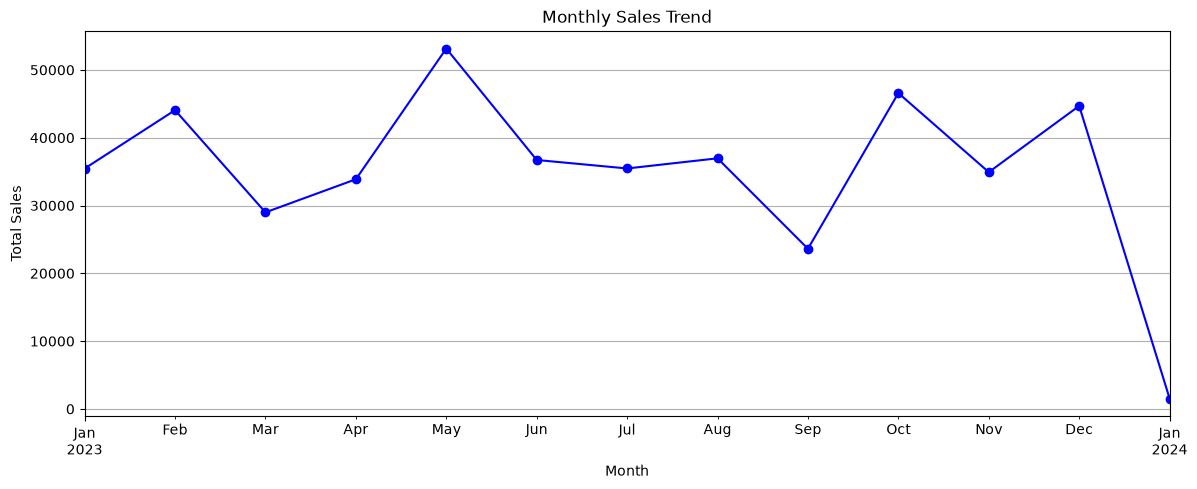

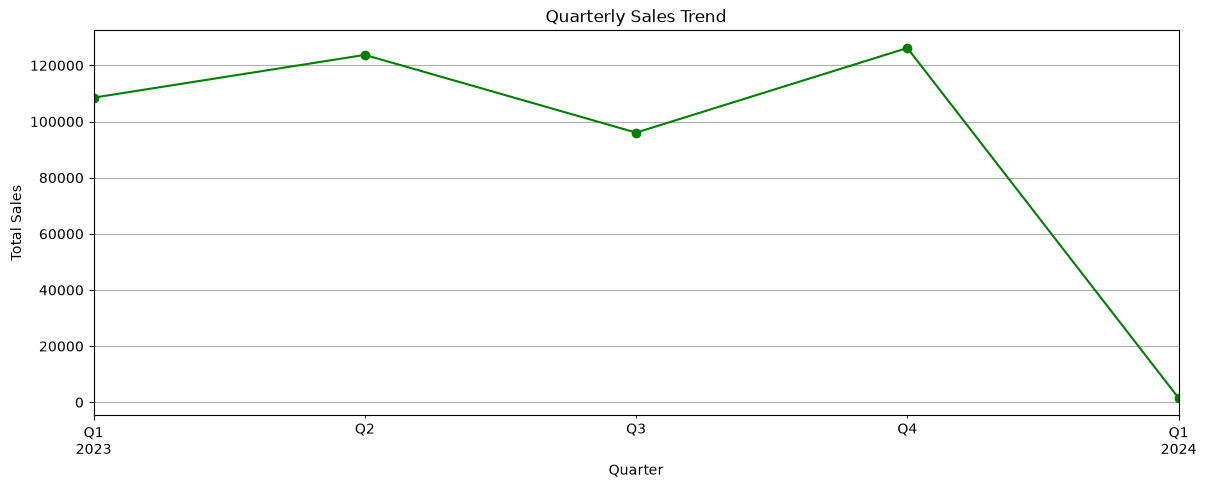

In [3]:
# Convert Date column to datetime object
df['Date'] = pd.to_datetime(df['Date'])

# Extract Month and Quarter
df['Month_Year'] = df['Date'].dt.to_period('M')
df['Quarter'] = df['Date'].dt.to_period('Q')

# Aggregate sales
monthly_sales = df.groupby('Month_Year')['Total Amount'].sum()
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Plot Monthly Trends
plt.figure(figsize=(14, 5))
monthly_sales.plot(kind='line', marker='o', color='b')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

# Plot Quarterly Trends
plt.figure(figsize=(14, 5))
quarterly_sales.plot(kind='line', marker='o', color='g')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

### Observation
Monthly sales fluctuate throughout the year. May recorded the highest sales, while September had the lowest sales among the complete 2023 months. This suggests some seasonal variation in customer spending.

### Observation
Quarterly sales were strongest in Q4 and Q2, while Q3 recorded the lowest sales. The business may benefit from investigating the factors responsible for the weaker Q3 performance.

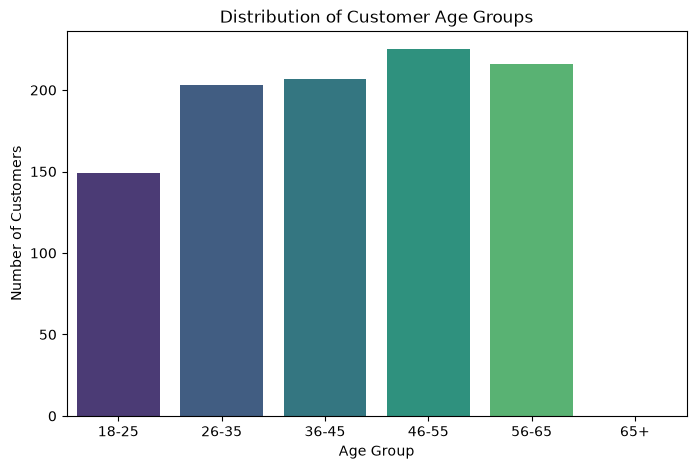

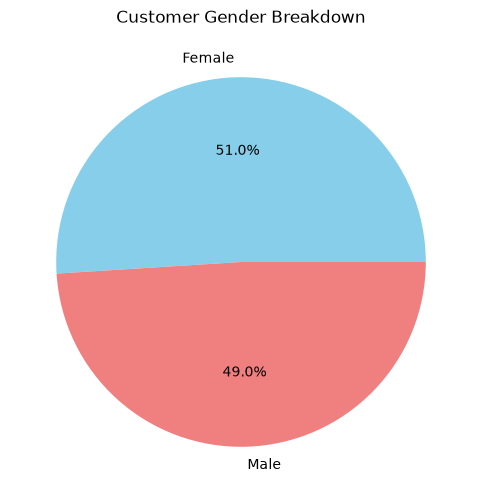

In [4]:
# Age Group Distribution
bins = [18, 25, 35, 45, 55, 65, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Age Group', palette='viridis')
plt.title('Distribution of Customer Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.show()

# Gender Breakdown
plt.figure(figsize=(6, 6))
df['Gender'].value_counts().plot.pie(autopct='%1.1f%%', colors=['skyblue', 'lightcoral'])
plt.title('Customer Gender Breakdown')
plt.ylabel('')
plt.show()

### Observation
Customers aged 46–55 form the largest age group, followed closely by customers aged 56–65. The 18–25 group has the lowest representation, suggesting that most customers are middle-aged.

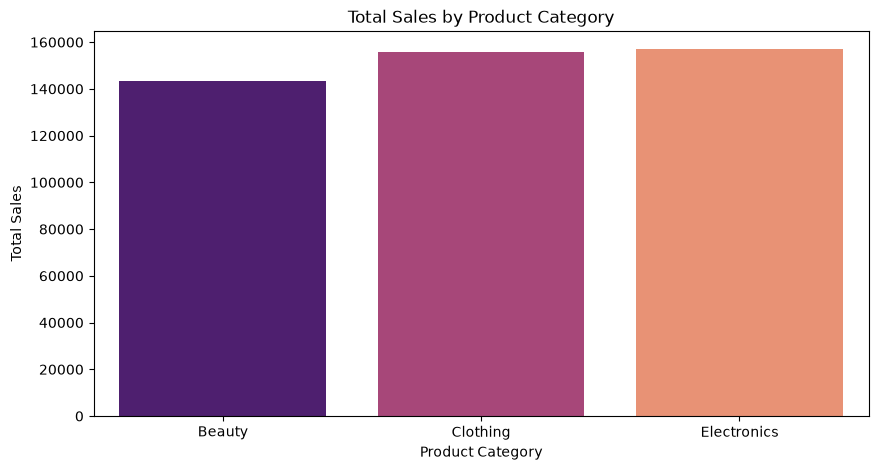

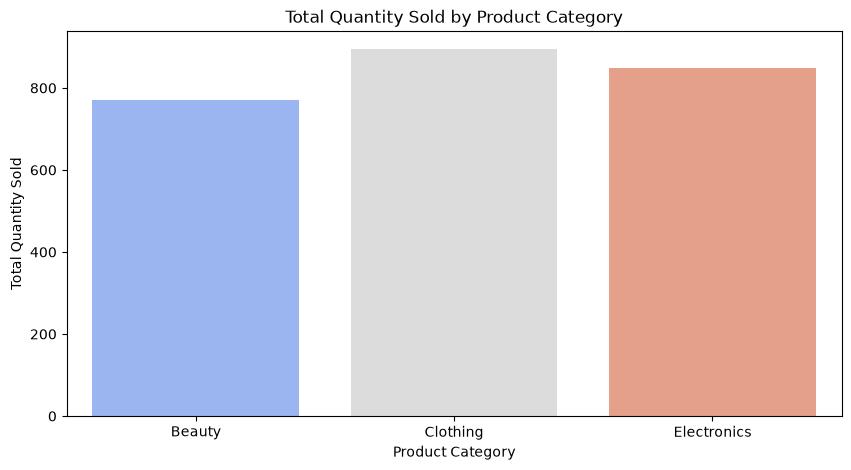

In [5]:
# Sales by Product Category
category_sales = df.groupby('Product Category')['Total Amount'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=category_sales, x='Product Category', y='Total Amount', palette='magma')
plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.show()

# Top Products by Quantity Sold
top_products = df.groupby('Product Category')['Quantity'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_products, x='Product Category', y='Quantity', palette='coolwarm')
plt.title('Total Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.show()

### Observation
Electronics generated the highest sales revenue, closely followed by Clothing, while Beauty generated the lowest revenue.

In [6]:
top_categories = (
    df.groupby('Product Category')['Quantity']
      .sum()
      .sort_values(ascending=False)
)

top_categories

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

### Observation
Clothing recorded the highest quantity sold with 894 units, followed by Electronics with 849 units and Beauty with 771 units.

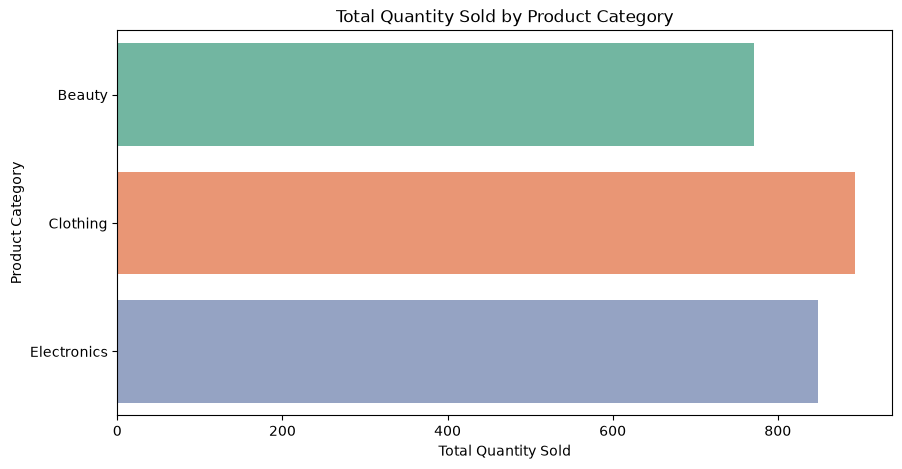

In [7]:

top_products = df.groupby('Product Category')["Quantity"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_products,
    x="Quantity",
    y="Product Category",
    palette="Set2",
     hue="Product Category",
    legend=False,
)
plt.title("Total Quantity Sold by Product Category")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Category")
plt.show()

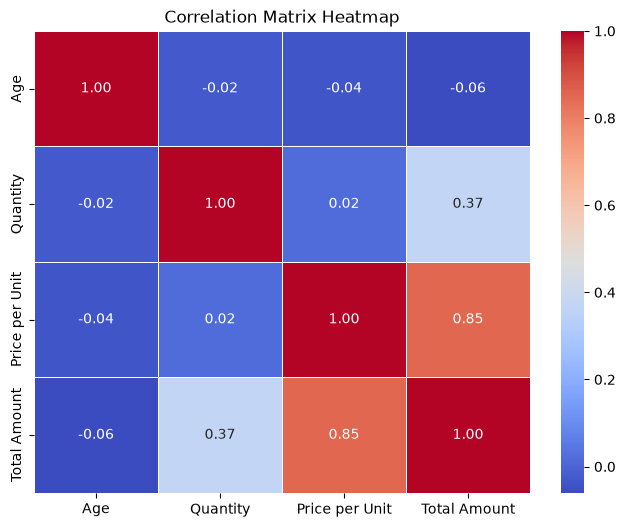

In [8]:
# Select the meaningful numerical columns (excluding Transaction ID as it's just an identifier)
numerical_df = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']]

# Calculate the correlation matrix
corr_matrix = numerical_df.corr()

# Set the figure size
plt.figure(figsize=(8, 6))

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add a title
plt.title('Correlation Matrix Heatmap')

# Display the plot
plt.show()

### Observation
Price per Unit has a strong positive correlation (0.85) with Total Amount, while Quantity has a moderate positive correlation (0.37). Age has almost no relationship with the amount customers spend.

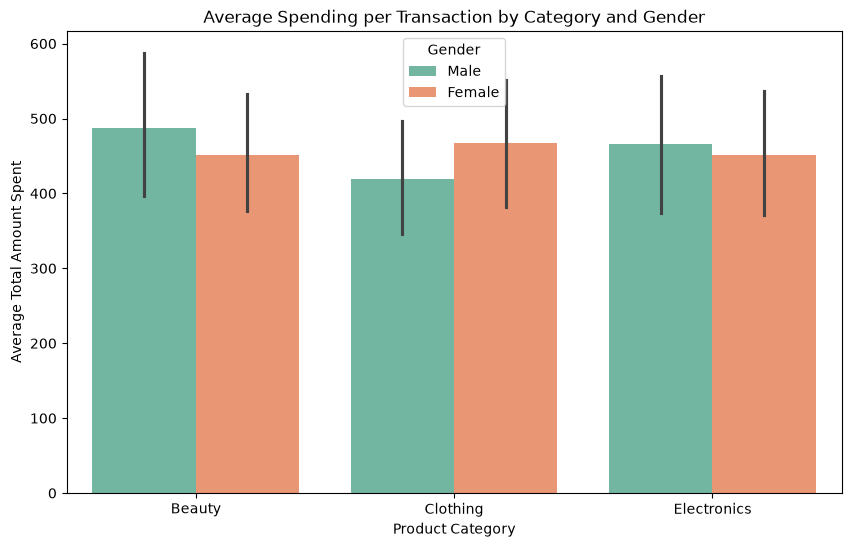

In [9]:
# Set the figure size
plt.figure(figsize=(10, 6))

# Plot average spending by Category, split by Gender
sns.barplot(data=df, x='Product Category', y='Total Amount', hue='Gender', palette='Set2')

# Add titles and labels
plt.title('Average Spending per Transaction by Category and Gender')
plt.xlabel('Product Category')
plt.ylabel('Average Total Amount Spent')

# Display the plot
plt.show()

### Observation
Male customers spend slightly more on Beauty and Electronics transactions, while female customers spend more on Clothing. This shows that spending patterns vary slightly across product categories by gender.

## Conclusion and Business Recommendations

1. The business should maintain strong inventory and marketing efforts for Electronics and Clothing because they generate the highest revenue and sales volume.

2. Promotions and discounts should be considered during weaker sales periods such as Q3, particularly around September, while inventory should be increased ahead of stronger periods such as Q4.

3. Customers aged 46–65 represent a large portion of the customer base, so targeted loyalty programmes and promotions could help increase repeat purchases from this group.

4. Since the gender distribution is nearly equal, marketing should target both genders while using category-specific promotions based on their different spending patterns.